In [25]:
from multiclass_functions import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os
os.makedirs('results', exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cpu


In [26]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
new_model_train = True
model_type = 'CNN'
dataset = 'MNIST'
save_model_path = f'results/{model_type}_{dataset}.pt'

In [27]:
transform = transforms.ToTensor()
train_DS= datasets.MNIST(root = 'data', train = True, download = True, transform = transform)
test_DS = datasets.MNIST(root = 'data', train = False, download = True, transform = transform)
train_DL = DataLoader(train_DS, batch_size = BATCH_SIZE, shuffle = True)
test_DL = DataLoader(test_DS, batch_size = BATCH_SIZE, shuffle = True)

['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
{'0 - zero': 0, '1 - one': 1, '2 - two': 2, '3 - three': 3, '4 - four': 4, '5 - five': 5, '6 - six': 6, '7 - seven': 7, '8 - eight': 8, '9 - nine': 9}
torch.Size([32, 1, 28, 28])
1 - one


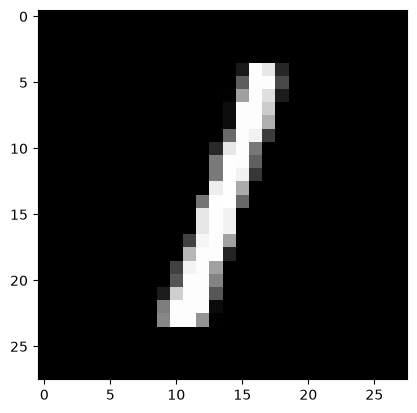

In [28]:
print(test_DS.classes)
print(test_DS.class_to_idx)

x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

plt.imshow(x_batch[0,0], cmap = 'gray')
print(test_DS.classes[y_batch[0]])

In [ ]:
class CNN(nn.Module):                                               # x_batch.shape -> (32, 1, 28, 28)
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(nn.Conv2d(1, 8, 3, padding = 1),     # (32,8,28,28)
                                    nn.BatchNorm2d(8),
                                    nn.ReLU(),
                                    )
        self.Maxpool1 = nn.MaxPool2d(2)                                 # (32,8,14,14)
        self.conv2 = nn.Sequential(nn.Conv2d(8, 16, 3, padding=1),      # (32,16,14,14)
                                    nn.BatchNorm2d(16),
                                    nn.ReLU()
                                    )
        self.Maxpool2 = nn.MaxPool2d(2)                                 # (32,16,7,7)
        self.conv3 = nn.Sequential(nn.Conv2d(16, 32,3, padding=1),      # (32,32,7,7)
                                    nn.BatchNorm2d(32),
                                    nn.ReLU()
                                    )
        self.Maxpool3 = nn.MaxPool2d(2)                                 # (32,32,3.5,3.5) -> MaxPool1의 기본설정 ceil_mode=False(소수점 버림)  => (32,32,3,3)
        self.fc = nn.Linear(32*3*3, 10)    

    def forward(self, x):
        x = self.conv1(x)
        x = self.Maxpool1(x)
        x = self.conv2(x)
        x = self.Maxpool2(x)
        x = self.conv3(x)
        x = self.Maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.convblock1 = nn.Sequential(nn.Conv2d(1,32,3, padding=1),
                                        nn.BatchNorm2d(32),
                                        nn.ReLU(),
                                        nn.Conv2d(32, 32,3,padding=1),
                                        nn.BatchNorm2d(32),
                                        nn.ReLU()
                                        )
        self.Maxpool1 = nn.MaxPool2d(2) 

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                        nn.BatchNorm2d(64),
                                        nn.ReLU(),
                                        nn.Conv2d(64,64,3,padding=1),
                                        nn.BatchNorm2d(64),
                                        nn.ReLU(),
                                        nn.Conv2d(64,64,3,padding=1) ,
                                        nn.BatchNorm2d(64),
                                        nn.ReLU()
                                        )
        self.Maxpool2 = nn.MaxPool2d(2)

        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1),
                                        nn.BatchNorm2d(128),
                                        nn.ReLU(),
                                        nn.Conv2d(128,128,3,padding=1) ,
                                        nn.BatchNorm2d(128),
                                        nn.ReLU()
                                        )
        self.Maxpool2 = nn.MaxPool2d(2)
                

In [30]:
model = globals()[model_type]().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(DEVICE)).shape)

CNN(
  (conv1): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Sequential(
    (0): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (Maxpool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=288, out_features=10, bias=True)
)
torch.Size([32, 

Epoch : 1, train loss : 0.149
------------------------------
Epoch : 2, train loss : 0.049
------------------------------
Epoch : 3, train loss : 0.038
------------------------------
Epoch : 4, train loss : 0.031
------------------------------
Epoch : 5, train loss : 0.026
------------------------------


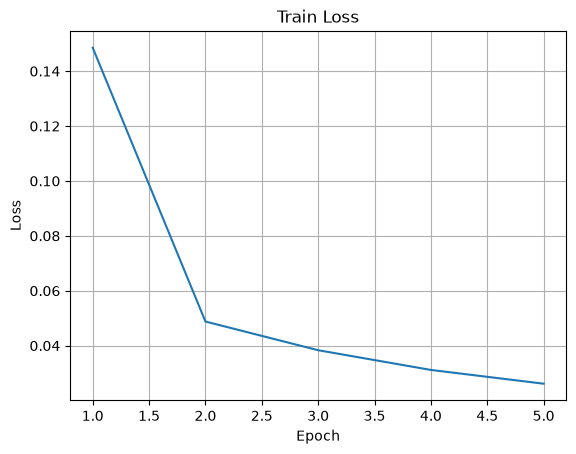

In [31]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr = LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Train Loss')
    plt.grid()

In [34]:
load_model = torch.load(save_model_path, map_location=DEVICE, weights_only=False)


(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 [Text(0, 0, '0 - zero'),
  Text(1, 0, '1 - one'),
  Text(2, 0, '2 - two'),
  Text(3, 0, '3 - three'),
  Text(4, 0, '4 - four'),
  Text(5, 0, '5 - five'),
  Text(6, 0, '6 - six'),
  Text(7, 0, '7 - seven'),
  Text(8, 0, '8 - eight'),
  Text(9, 0, '9 - nine')])

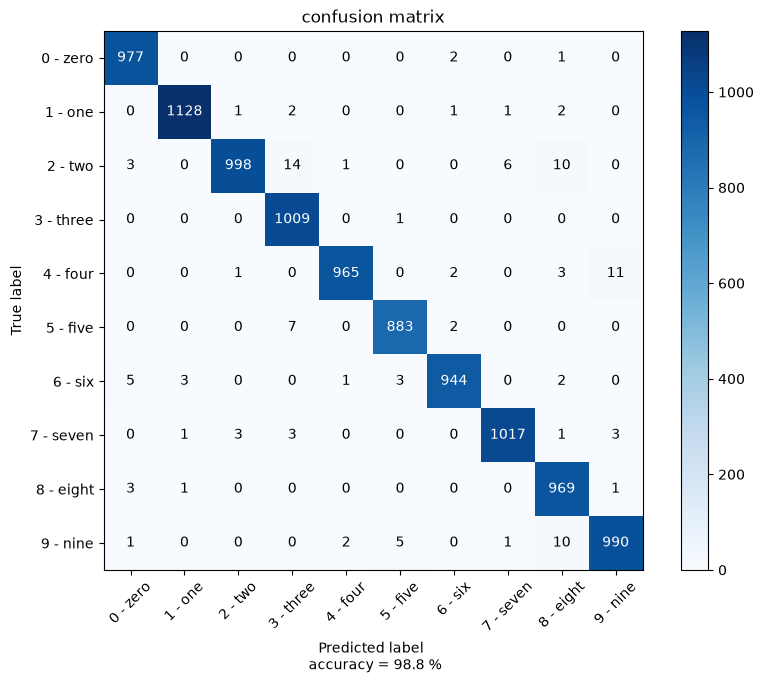

In [35]:
confusion = get_conf(load_model, test_DL)
plot_confusion_matrix(confusion, test_DS.classes)
plt.xticks(rotation=45)